In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/matthewsenahey/falciparum-thick/ReadMe_new_2021.docx
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_115923.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_120624.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_115749.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_115616.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_120431.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_121814.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_121540.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_113312.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_121141.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc563/20170727_120159.jpg
/kaggle/input/datasets/matthewsenahey/falciparum-thick/TF37_Sc56

In [2]:
#Cell 1
!pip install ultralytics --quiet

import os, math, random, glob, shutil
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from collections import Counter
Image.MAX_IMAGE_PIXELS = None  # allow the large NIH images

import ultralytics
ultralytics.checks()   # confirms GPU (Tesla T4)

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7035.6/8062.4 GB disk)


In [3]:
#Cell 2
BASE = '/kaggle/input/datasets/matthewsenahey/falciparum-thick'
GT   = os.path.join(BASE, 'GT_updated')
OUT  = '/kaggle/working/yolo_tiles'

TILE = 640          # tile size (matches YOLO training size)
OVERLAP = 0.20      # 20% overlap so boundary parasites aren't lost
STRIDE = int(TILE * (1 - OVERLAP))   # 512
KEEP_EMPTY_FRACTION = 0.0            # drop tiles with no parasites

random.seed(42)   # reproducible split + tiling

# --- gather patients and split at PATIENT level (no leakage) ---
patients = sorted([d for d in os.listdir(BASE)
                   if os.path.isdir(os.path.join(BASE, d)) and d != 'GT_updated'])
random.shuffle(patients)
n = len(patients); n_train = int(n*0.70); n_val = int(n*0.15)
split_map = {}
for i, pat in enumerate(patients):
    split_map[pat] = 'train' if i < n_train else ('val' if i < n_train+n_val else 'test')
print("Patients:", len(patients), "->", dict(Counter(split_map.values())))

def parse_parasites(txt_path):
    """Return (img_w, img_h, [(cx,cy,w,h) px]) for parasites only."""
    with open(txt_path) as f:
        lines = f.read().splitlines()
    if not lines: return None, None, []
    h = lines[0].split(','); img_w, img_h = int(h[1]), int(h[2])
    boxes = []
    for ln in lines[1:]:
        p = ln.split(',')
        if len(p) < 9: continue
        if p[1] == 'Parasite' and p[3] == 'Circle':
            x1,y1 = float(p[5]),float(p[6]); x2,y2 = float(p[7]),float(p[8])
            r = max(math.hypot(x2-x1, y2-y1), 12)
            boxes.append((x1, y1, 2*r, 2*r))
    return img_w, img_h, boxes

# --- fresh output dirs ---
if os.path.exists(OUT): shutil.rmtree(OUT)
for sp in ['train','val','test']:
    os.makedirs(f'{OUT}/images/{sp}', exist_ok=True)
    os.makedirs(f'{OUT}/labels/{sp}', exist_ok=True)

stats = {sp:{'tiles':0,'boxes':0,'empty':0} for sp in ['train','val','test']}

for pat in patients:
    sp = split_map[pat]
    gt_dir = os.path.join(GT, pat); img_dir = os.path.join(BASE, pat)
    if not os.path.isdir(gt_dir): continue
    for t in os.listdir(gt_dir):
        if not t.endswith('.txt'): continue
        img_name = t.replace('.txt','.jpg')
        img_path = os.path.join(img_dir, img_name)
        if not os.path.exists(img_path): continue
        img_w, img_h, boxes = parse_parasites(os.path.join(gt_dir, t))
        if img_w is None or len(boxes) == 0: continue
        try:
            im = Image.open(img_path).convert('RGB')
        except Exception:
            continue
        W, H = im.size

        xs = list(range(0, max(W - TILE, 0) + 1, STRIDE)) or [0]
        ys = list(range(0, max(H - TILE, 0) + 1, STRIDE)) or [0]
        if W > TILE and xs[-1] != W - TILE: xs.append(W - TILE)
        if H > TILE and ys[-1] != H - TILE: ys.append(H - TILE)

        for ty in ys:
            for tx in xs:
                tile_boxes = []
                for (cx,cy,bw,bh) in boxes:
                    if tx <= cx < tx+TILE and ty <= cy < ty+TILE:
                        tile_boxes.append(((cx-tx)/TILE, (cy-ty)/TILE,
                                           min(bw/TILE,1.0), min(bh/TILE,1.0)))
                if not tile_boxes:
                    if random.random() >= KEEP_EMPTY_FRACTION:
                        stats[sp]['empty'] += 1
                        continue
                stem = f"{pat}__{t.replace('.txt','')}__x{tx}_y{ty}"
                im.crop((tx, ty, tx+TILE, ty+TILE)).save(
                    f'{OUT}/images/{sp}/{stem}.jpg', quality=90)
                with open(f'{OUT}/labels/{sp}/{stem}.txt','w') as lf:
                    for (ncx,ncy,nw,nh) in tile_boxes:
                        lf.write(f"0 {ncx:.6f} {ncy:.6f} {nw:.6f} {nh:.6f}\n")
                stats[sp]['tiles'] += 1
                stats[sp]['boxes'] += len(tile_boxes)

print("\n=== TILING COMPLETE ===")
for sp in ['train','val','test']:
    s = stats[sp]; avg = s['boxes']/s['tiles'] if s['tiles'] else 0
    print(f"  {sp:5}: {s['tiles']:6} tiles, {s['boxes']:7} boxes (avg {avg:.1f}/tile), {s['empty']} empty dropped")

with open(f'{OUT}/data.yaml','w') as f:
    f.write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames: ['parasite']\n")
print(f"\nWrote {OUT}/data.yaml")

Patients: 150 -> {'train': 105, 'val': 22, 'test': 23}

=== TILING COMPLETE ===
  train:  23211 tiles,   98372 boxes (avg 4.2/tile), 38229 empty dropped
  val  :   4734 tiles,   21015 boxes (avg 4.4/tile), 7890 empty dropped
  test :   4712 tiles,   19285 boxes (avg 4.1/tile), 8248 empty dropped

Wrote /kaggle/working/yolo_tiles/data.yaml


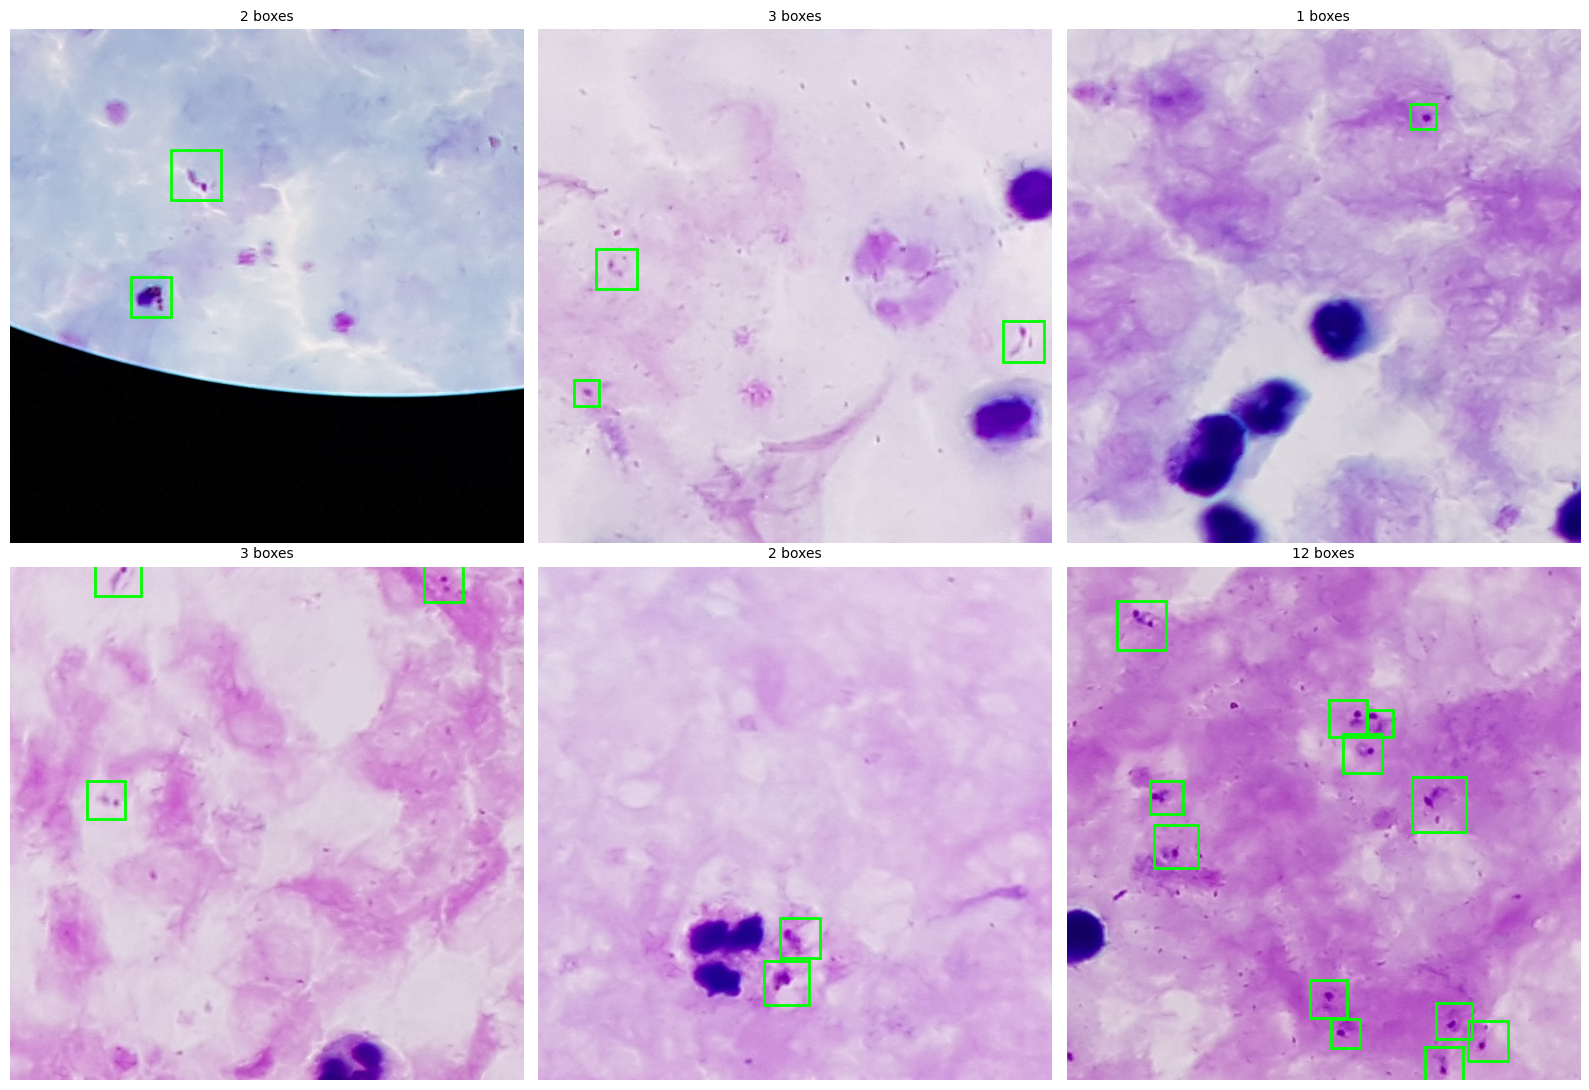

VERIFY: green boxes must sit on the dark-purple parasites within each tile.


In [4]:
#Cell 3
OUT = '/kaggle/working/yolo_tiles'
tiles = glob.glob(f'{OUT}/labels/train/*.txt')
random.seed(1); random.shuffle(tiles)

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, lbl_path in zip(axes.flat, tiles[:6]):
    stem = os.path.basename(lbl_path).replace('.txt','')
    im = Image.open(f'{OUT}/images/train/{stem}.jpg'); W, H = im.size
    ax.imshow(im); n = 0
    for ln in open(lbl_path):
        p = ln.split()
        if len(p) != 5: continue
        _, ncx, ncy, nw, nh = p
        cx, cy, w, h = float(ncx)*W, float(ncy)*H, float(nw)*W, float(nh)*H
        ax.add_patch(patches.Rectangle((cx-w/2, cy-h/2), w, h,
                     linewidth=2, edgecolor='lime', facecolor='none'))
        n += 1
    ax.set_title(f"{n} boxes", fontsize=10); ax.axis('off')
plt.tight_layout(); plt.show()
print("VERIFY: green boxes must sit on the dark-purple parasites within each tile.")

In [5]:
#Cell 4
from ultralytics import YOLO

model = YOLO('yolov8n.pt')   # nano, TF.js-exportable

results = model.train(
    data='/kaggle/working/yolo_tiles/data.yaml',
    epochs=60,
    imgsz=640,           # matches tile size — parasites stay resolvable
    batch=32,            # 640px tiles are light; large batch stabilizes training
    patience=15,
    device=0,
    project='/kaggle/working/runs',
    name='parasite_tiled',
    plots=True,
    val=True
)
print("\nBest weights: /kaggle/working/runs/parasite_tiled/weights/best.pt")

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_tiles/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=parasite_tiled, nbs=64, 

In [6]:
#Cell 5
from ultralytics import YOLO

best = YOLO('/kaggle/working/runs/parasite_tiled/weights/best.pt')

metrics = best.val(
    data='/kaggle/working/yolo_tiles/data.yaml',
    split='test',        # patient-held-out test tiles — the honest number
    imgsz=640,
    device=0
)
print("\n=== TEST-SET PERFORMANCE ===")
print(f"  mAP50    : {metrics.box.map50:.4f}")
print(f"  mAP50-95 : {metrics.box.map:.4f}")
print(f"  Precision: {metrics.box.mp:.4f}")
print(f"  Recall   : {metrics.box.mr:.4f}")

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1045.2±305.8 MB/s, size: 42.9 KB)
val: Scanning /kaggle/working/yolo_tiles/labels/test... 4712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4712/4712 1.3Kit/s 3.6s
val: New cache created: /kaggle/working/yolo_tiles/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 295/295 8.1it/s 36.5s
                   all       4712      19285      0.824      0.774       0.81      0.318
Speed: 0.9ms preprocess, 3.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs/detect/val

=== TEST-SET PERFORMANCE ===
  mAP50    : 0.8096
  mAP50-95 : 0.3184
  Precision: 0.8242
  Recall   : 0.7735


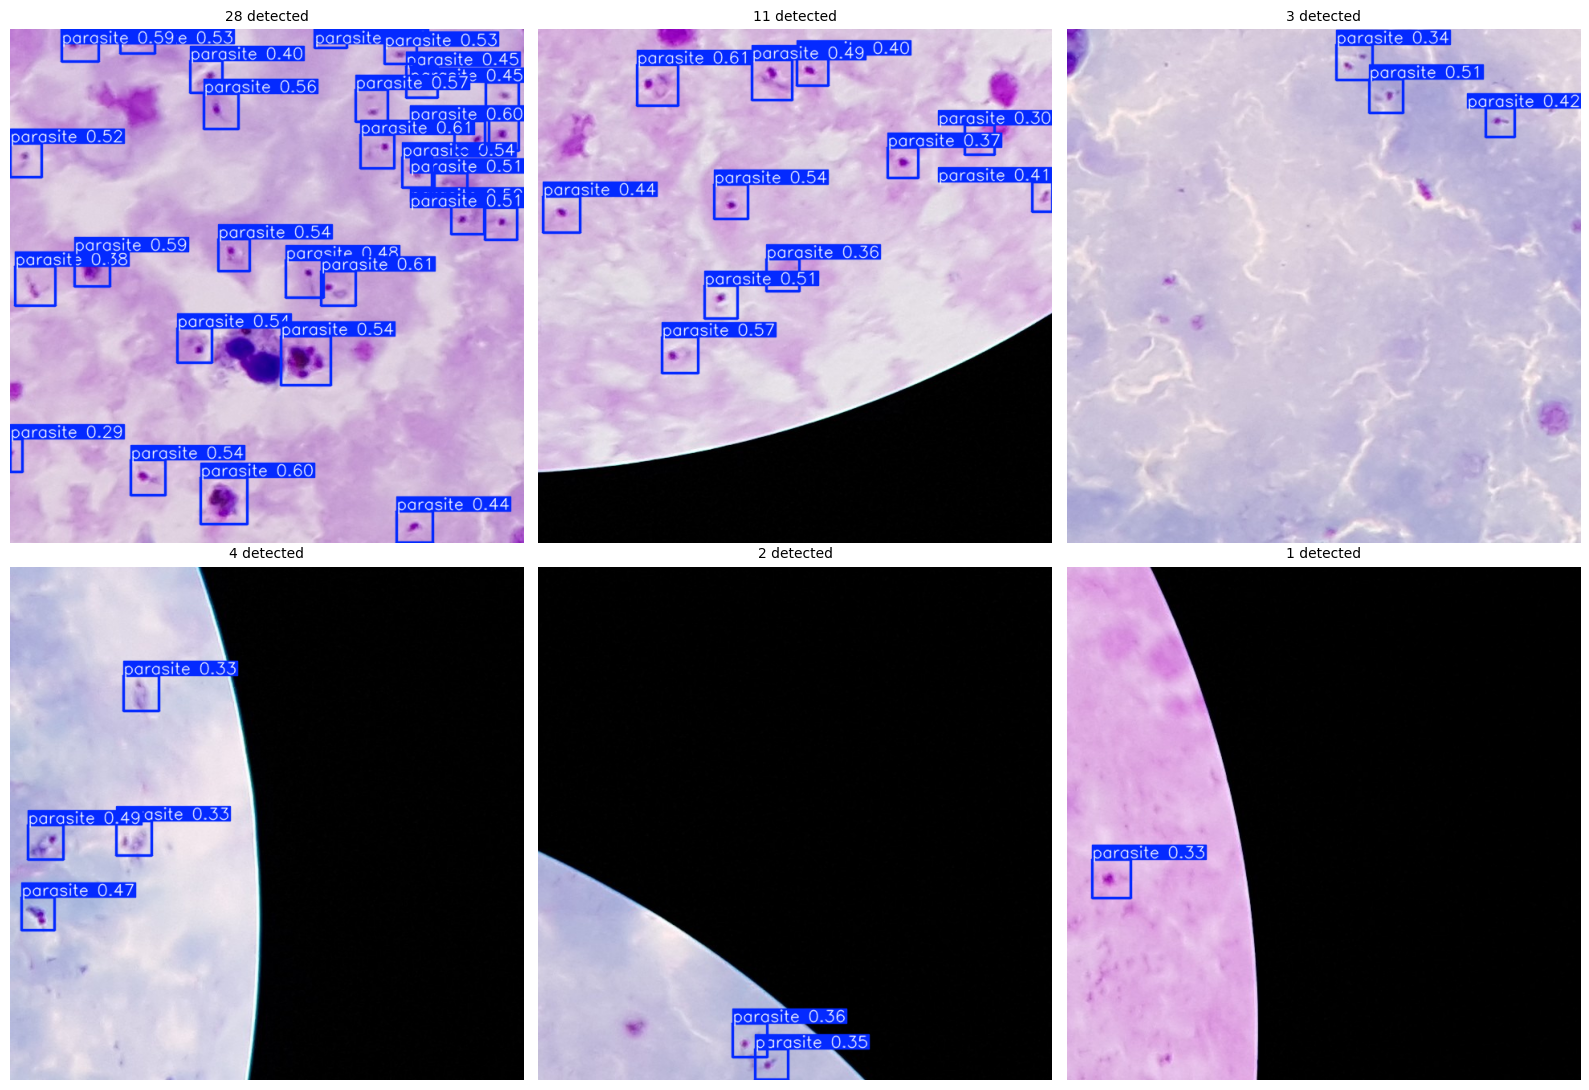

Boxes = model detections on unseen TEST tiles.


In [7]:
#Cell 6
import glob, random
import matplotlib.pyplot as plt
from ultralytics import YOLO

best = YOLO('/kaggle/working/runs/parasite_tiled/weights/best.pt')
OUT = '/kaggle/working/yolo_tiles'

test_imgs = glob.glob(f'{OUT}/images/test/*.jpg')
random.seed(3); random.shuffle(test_imgs)
picks = test_imgs[:6]

preds = best.predict(picks, imgsz=640, conf=0.25, device=0, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, r in zip(axes.flat, preds):
    # .plot() returns the image (BGR numpy) with detections already drawn
    annotated = r.plot()                      # includes boxes
    ax.imshow(annotated[:, :, ::-1])          # BGR -> RGB for matplotlib
    ax.set_title(f"{len(r.boxes)} detected", fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()
print("Boxes = model detections on unseen TEST tiles.")

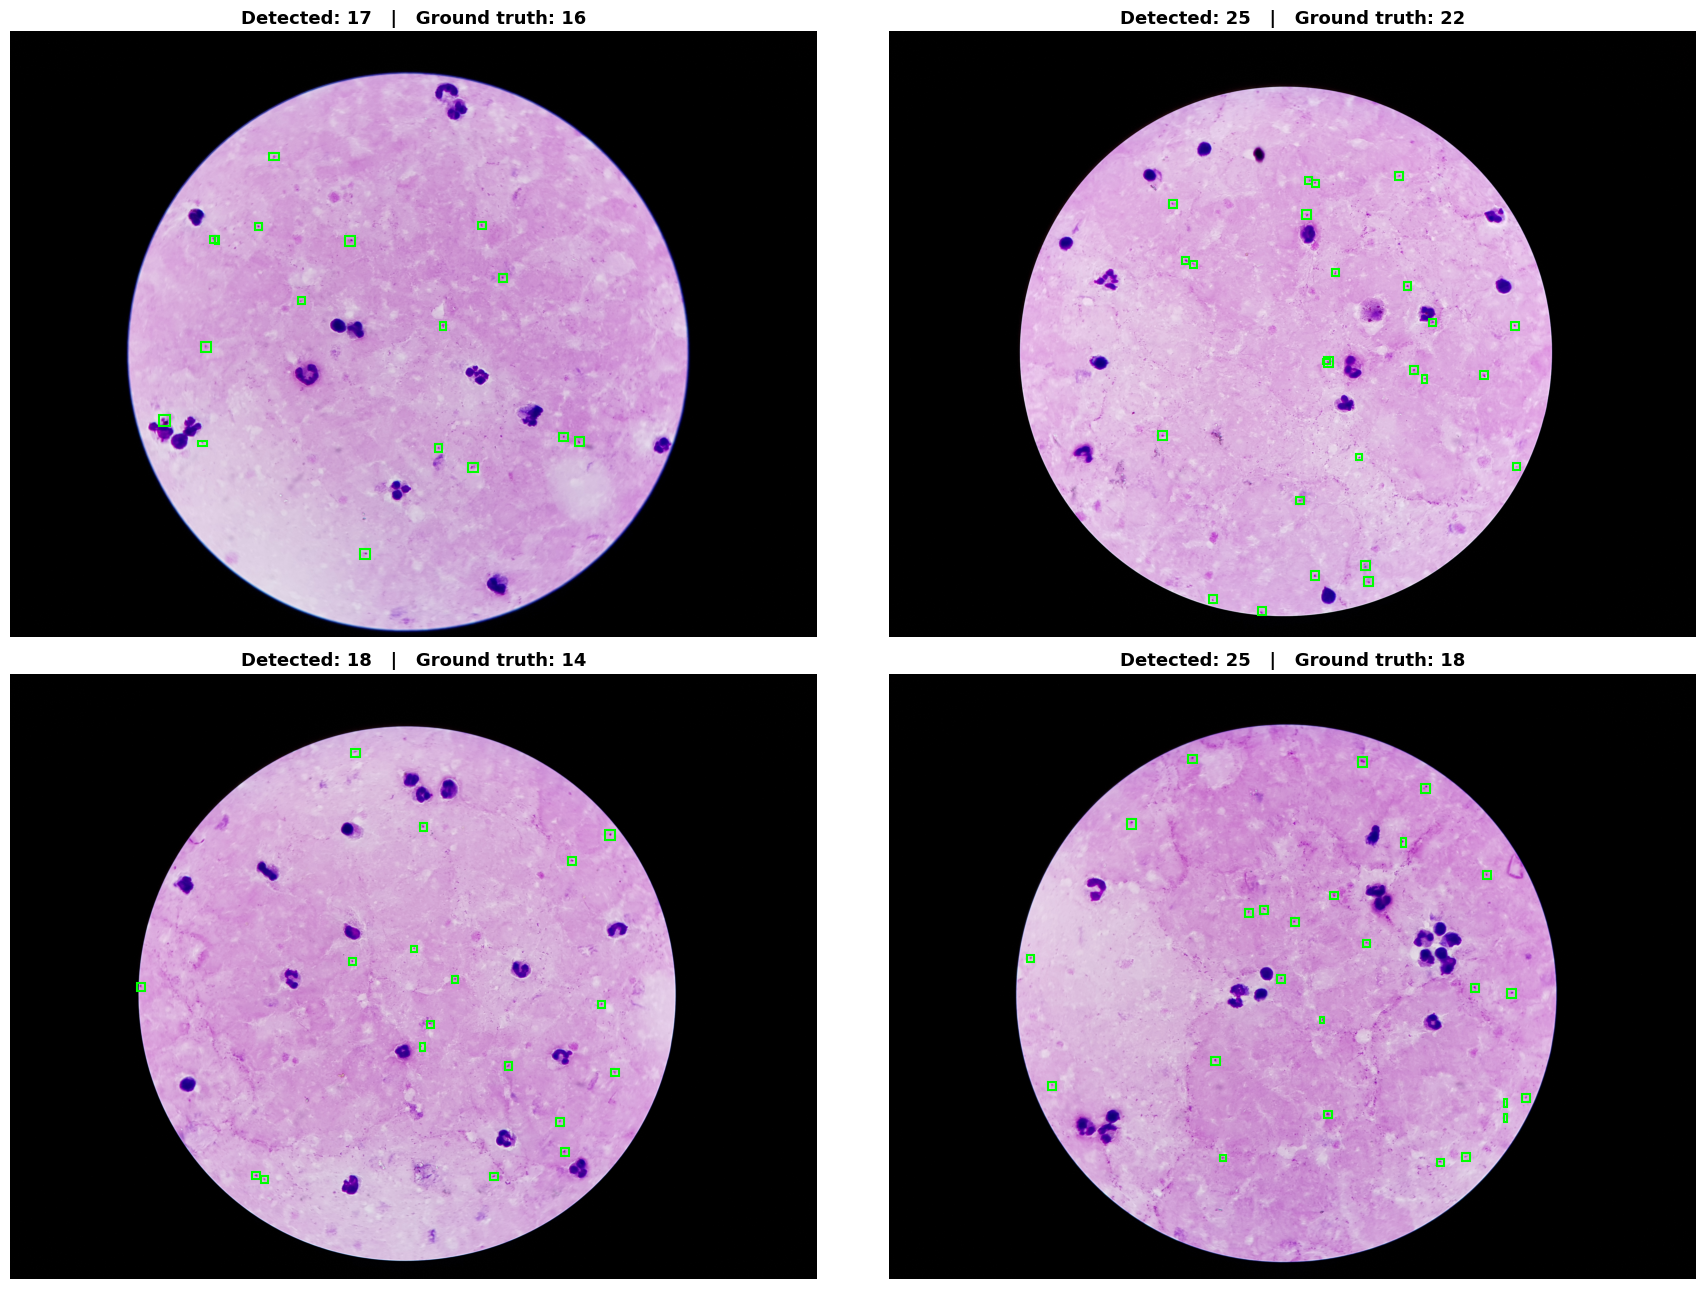

Confidence threshold: 0.25   |   NMS de-dup IoU: 0.4
Compare 'Detected' vs 'Ground truth' — they should be close.


In [8]:
#Cell 7
import os, glob, math, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO
Image.MAX_IMAGE_PIXELS = None

best = YOLO('/kaggle/working/runs/parasite_tiled/weights/best.pt')

BASE = '/kaggle/input/datasets/matthewsenahey/falciparum-thick'
GT   = os.path.join(BASE, 'GT_updated')
TILE = 640
OVERLAP = 0.20
STRIDE = int(TILE * (1 - OVERLAP))
CONF = 0.25          # confidence threshold for counting
IOU_MERGE = 0.4      # de-dup: boxes overlapping more than this are the same parasite

def iou(a, b):
    """IoU of two [x1,y1,x2,y2] boxes."""
    ax1,ay1,ax2,ay2 = a; bx1,by1,bx2,by2 = b
    ix1,iy1 = max(ax1,bx1), max(ay1,by1)
    ix2,iy2 = min(ax2,bx2), min(ay2,by2)
    iw, ih = max(0,ix2-ix1), max(0,iy2-iy1)
    inter = iw*ih
    if inter == 0: return 0.0
    ua = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
    return inter/ua

def nms(boxes, scores, thr):
    """Greedy non-max suppression → indices to keep."""
    idx = sorted(range(len(boxes)), key=lambda i: scores[i], reverse=True)
    keep = []
    while idx:
        i = idx.pop(0); keep.append(i)
        idx = [j for j in idx if iou(boxes[i], boxes[j]) < thr]
    return keep

def count_field(img_path, conf=CONF):
    """Tile → detect → merge → de-dup. Returns (PIL image, kept_boxes, count)."""
    im = Image.open(img_path).convert('RGB')
    W, H = im.size

    xs = list(range(0, max(W-TILE,0)+1, STRIDE)) or [0]
    ys = list(range(0, max(H-TILE,0)+1, STRIDE)) or [0]
    if W > TILE and xs[-1] != W-TILE: xs.append(W-TILE)
    if H > TILE and ys[-1] != H-TILE: ys.append(H-TILE)

    all_boxes, all_scores = [], []
    for ty in ys:
        for tx in xs:
            tile = im.crop((tx, ty, tx+TILE, ty+TILE))
            r = best.predict(tile, imgsz=640, conf=conf, device=0, verbose=False)[0]
            for box, sc in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                x1,y1,x2,y2 = box
                # map tile coords back to full-image coords
                all_boxes.append([x1+tx, y1+ty, x2+tx, y2+ty])
                all_scores.append(float(sc))

    if not all_boxes:
        return im, [], 0
    keep = nms(all_boxes, all_scores, IOU_MERGE)
    kept = [all_boxes[i] for i in keep]
    return im, kept, len(kept)

# --- Run on a few test-patient images and compare to ground truth ---
def gt_count(img_path):
    """Ground-truth parasite count from the annotation file."""
    pat = os.path.basename(os.path.dirname(img_path))
    stem = os.path.basename(img_path).replace('.jpg','.txt')
    gt_path = os.path.join(GT, pat, stem)
    if not os.path.exists(gt_path): return None
    with open(gt_path) as f:
        lines = f.read().splitlines()
    return sum(1 for ln in lines[1:]
               if len(ln.split())>=1 and ln.split(',')[1]=='Parasite' and ln.split(',')[3]=='Circle')

# pick test-split patients (reuse the same seed/split logic)
random.seed(42)
patients = sorted([d for d in os.listdir(BASE)
                   if os.path.isdir(os.path.join(BASE,d)) and d!='GT_updated'])
random.shuffle(patients)
n=len(patients); test_pats = patients[int(n*0.85):]

# grab a few full images from test patients that have parasites
samples = []
for pat in test_pats:
    gtd = os.path.join(GT, pat)
    if not os.path.isdir(gtd): continue
    for t in os.listdir(gtd):
        if t.endswith('.txt'):
            ip = os.path.join(BASE, pat, t.replace('.txt','.jpg'))
            if os.path.exists(ip) and (gt_count(ip) or 0) >= 5:
                samples.append(ip)
        if len(samples) >= 4: break
    if len(samples) >= 4: break

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for ax, ip in zip(axes.flat, samples):
    im, kept, count = count_field(ip)
    gt = gt_count(ip)
    ax.imshow(im)
    for (x1,y1,x2,y2) in kept:
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1,
                     linewidth=1.5, edgecolor='lime', facecolor='none'))
    ax.set_title(f"Detected: {count}   |   Ground truth: {gt}", fontsize=13, fontweight='bold')
    ax.axis('off')
plt.tight_layout(); plt.show()

print(f"Confidence threshold: {CONF}   |   NMS de-dup IoU: {IOU_MERGE}")
print("Compare 'Detected' vs 'Ground truth' — they should be close.")